In [39]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import seaborn as sns


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "legend.fontsize": 10,
})


In [40]:
def run_kathmandu_simulation(omega_vector=np.array([5.0, 10.0, 32.0])):
   
    m = 0.43             # Mass of FIFA regulation ball (kg)
    r = 0.11             # Radius of ball (m)
    A = np.pi * r**2     # Cross-sectional area (m^2)
    g = 9.81             # Gravity (m/s^2)
    
    altitude = 1400.0    # Kathmandu Valley altitude (m)
    mu = 1.81e-5         # Dynamic viscosity of air (Pa·s)
    omega = omega_vector # Angular velocity vector (rad/s)

    # --- Observation Data Points ---
    r0 = np.array([0.0, 0.0, 0.11])  # t = 0.00 s
    r1 = np.array([1.50, 0.45, 0.44])  # t = 0.05 s
    r2 = np.array([2.96, 0.86, 0.74])  # t = 0.10 s
    
   
    v0 = (r2 - r1) / 0.05

    # --- Aerodynamic Functions ---
    def get_Cd(v_mag):
        v_crit = 18.0
        Cd_turb, Cd_lam = 0.20, 0.42
        return Cd_lam - (Cd_lam - Cd_turb) / (1.0 + np.exp(-0.5 * (v_mag - v_crit)))

    def get_Cl(v_mag, omega_mag):
        if v_mag < 0.1 or omega_mag < 0.1:
            return 0.0
        spin_param = (omega_mag * r) / v_mag
        return 0.18 * np.tanh(2.0 * spin_param)

   
    def ode_system(t, state):
        x, y, z, vx, vy, vz = state
        v = np.array([vx, vy, vz])
        v_mag = np.linalg.norm(v)
        omega_mag = np.linalg.norm(omega)
        
        # Local air density adjusted for ball height z above Kathmandu
        current_rho = 1.225 * np.exp(-max(0.0, altitude + z) / 8450.0)
        Cd = get_Cd(v_mag)
        
        # 1. Quadratic Drag Acceleration Vector
        a_drag = - (current_rho * A * Cd / (2.0 * m)) * v_mag * v
        
        # 2. Magnus Acceleration Vector
        if omega_mag > 0 and v_mag > 0.1:
            Cl = get_Cl(v_mag, omega_mag)
            omega_hat = omega / omega_mag
            v_hat = v / v_mag
            a_magnus = (current_rho * A * r * Cl * omega_mag * v_mag / (2.0 * m)) * np.cross(omega_hat, v_hat)
        else:
            a_magnus = np.zeros(3)
            
        # 3. Gravitational Acceleration Vector
        a_grav = np.array([0.0, 0.0, -g])
        
        a_net = a_drag + a_magnus + a_grav
        return [vx, vy, vz, a_net[0], a_net[1], a_net[2]]

 
    def reach_goal(t, state):
        return state[0] - 11.0
    reach_goal.terminal = True
    reach_goal.direction = 1

    initial_state = [r0[0], r0[1], r0[2], v0[0], v0[1], v0[2]]

    # Numerical Integration
    sol = solve_ivp(
        ode_system, 
        t_span=(0.0, 1.0), 
        y0=initial_state, 
        events=reach_goal, 
        t_eval=np.linspace(0, 0.5, 200)
    )

    t_goal = sol.t_events[0][0]
    return t_goal, sol.y[0], sol.y[1], sol.y[2]


t_goal, x_traj, y_traj, z_traj = run_kathmandu_simulation()
final_y, final_z = y_traj[-1], z_traj[-1]

print(f"Flight Time to Goal Plane: {t_goal:.4f} s")
print(f"Goal Impact Coordinates: Y = {final_y:.3f} m, Z = {final_z:.3f} m")

Flight Time to Goal Plane: 0.3976 s
Goal Impact Coordinates: Y = 3.100 m, Z = 1.617 m


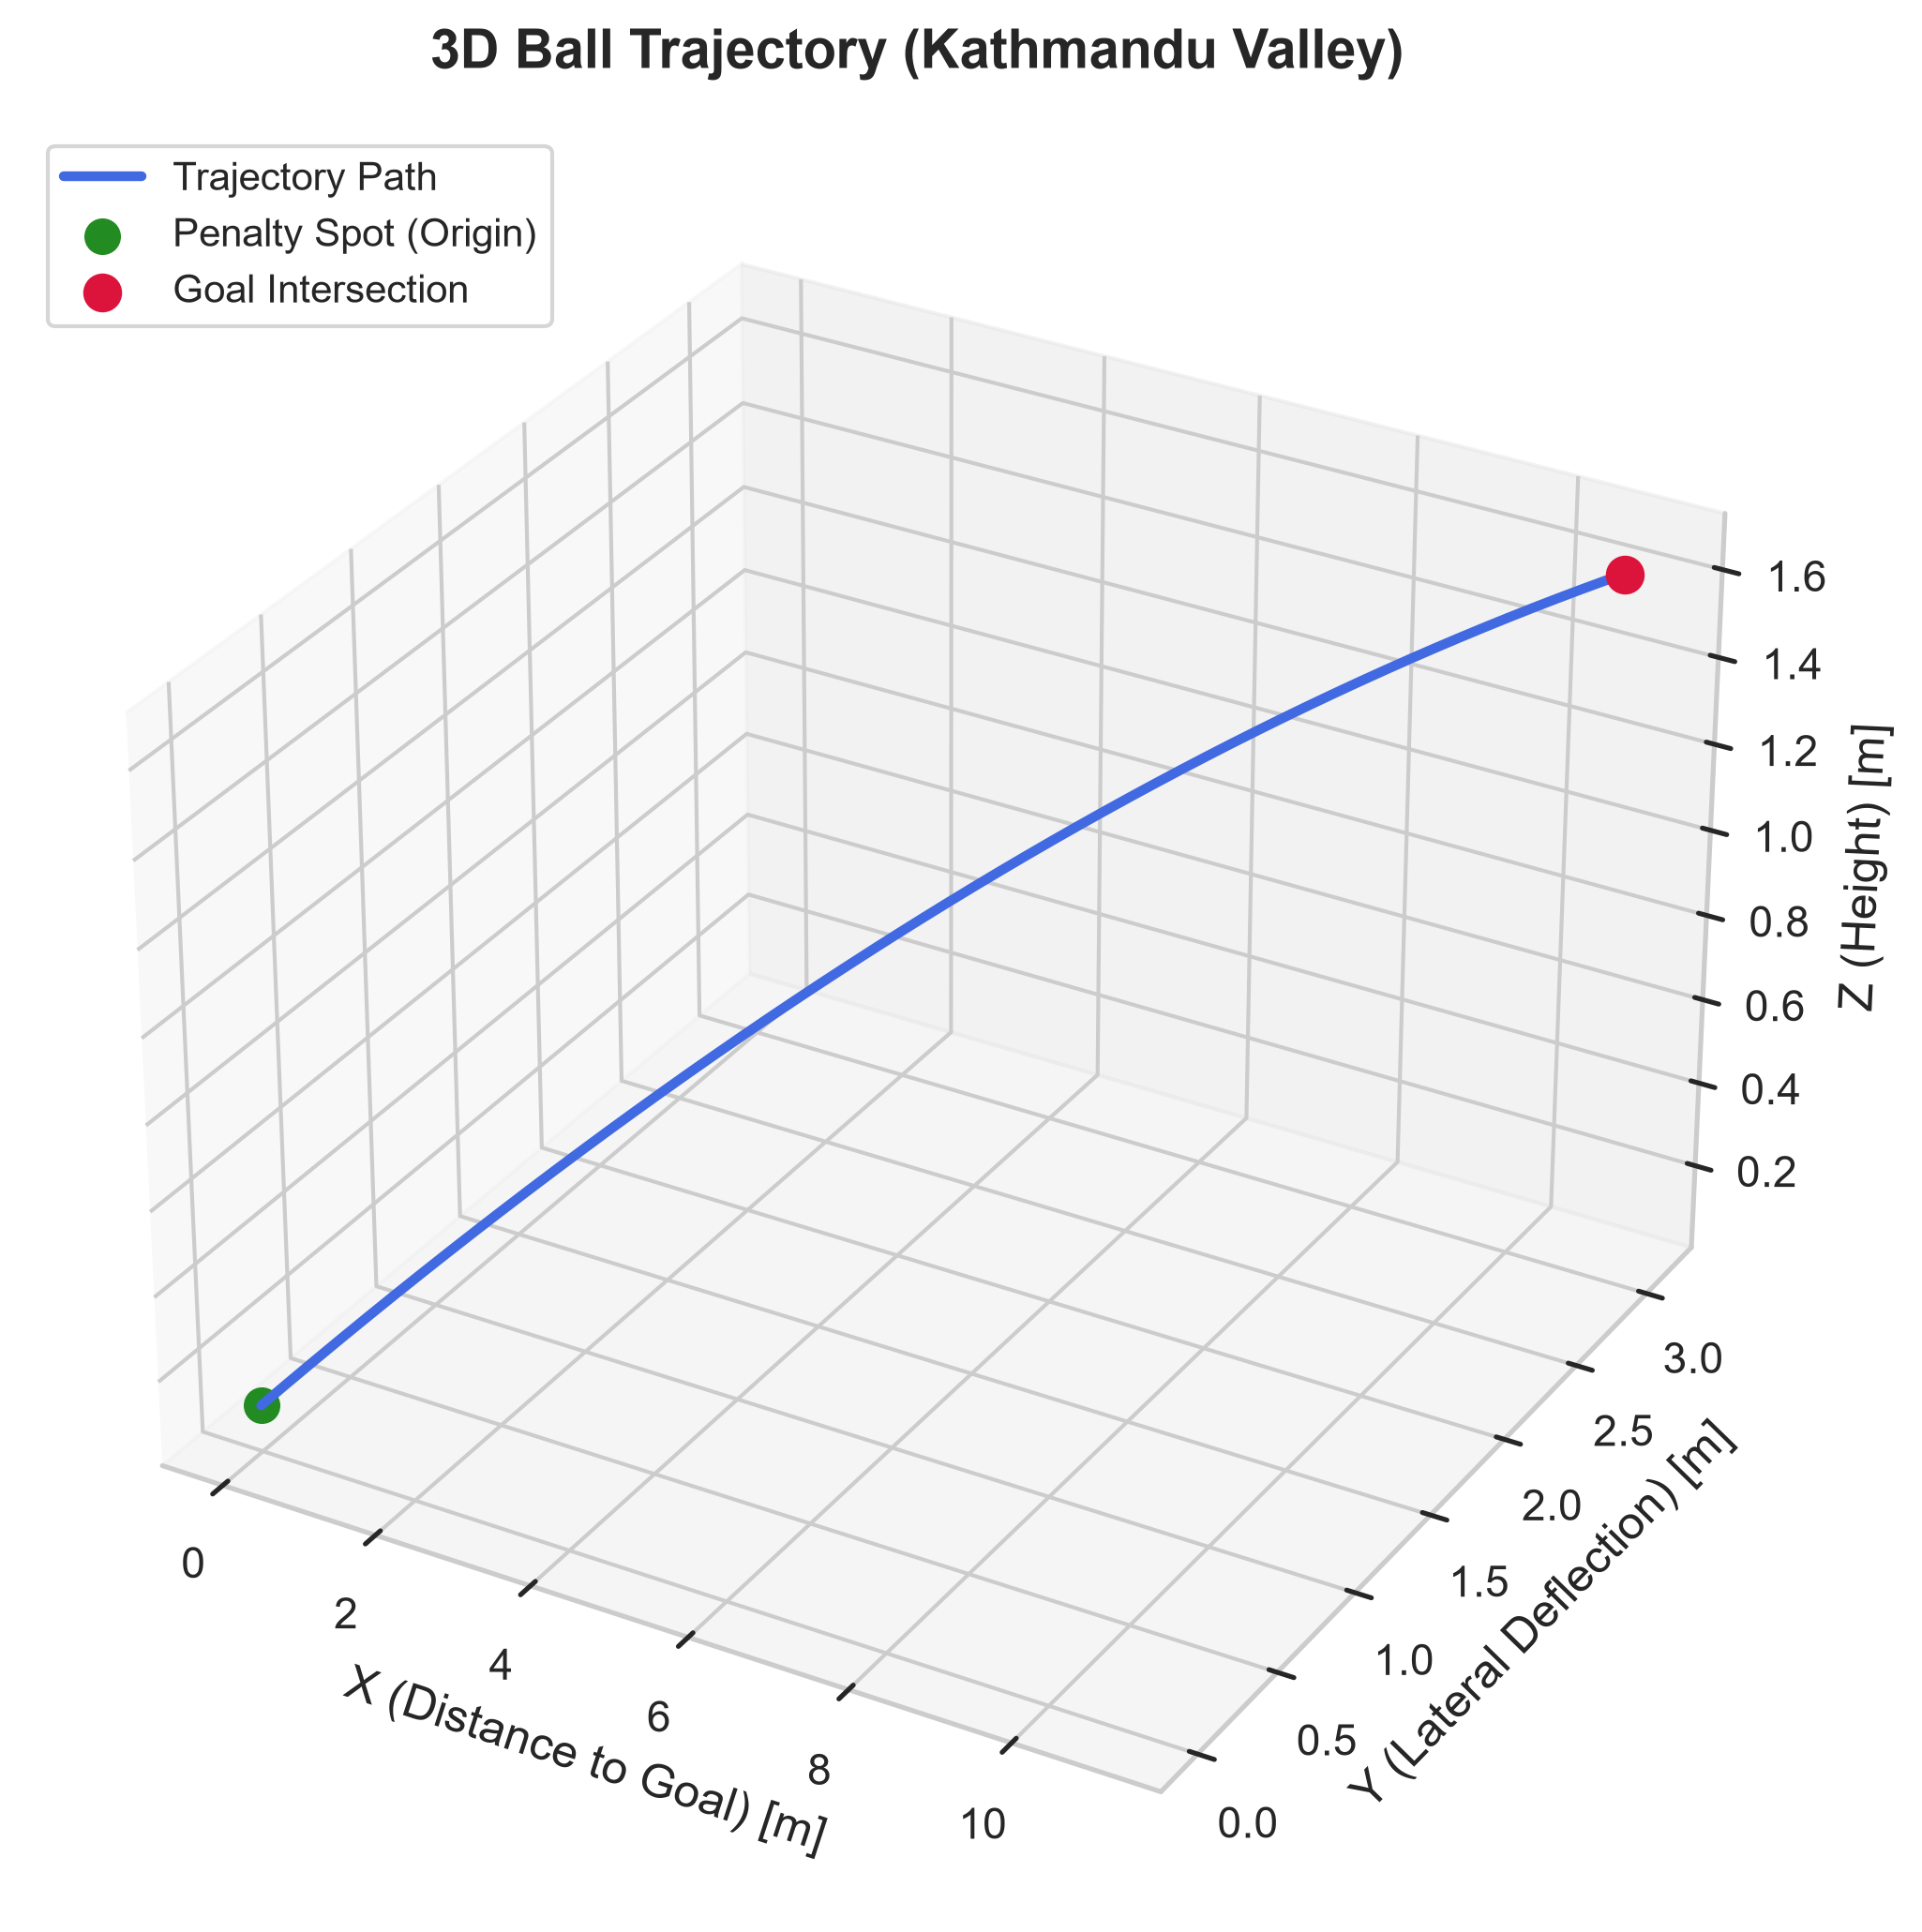

In [41]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')

ax.plot(x_traj, y_traj, z_traj, label='Trajectory Path', color='royalblue', lw=2.5)
ax.scatter([0], [0], [0.11], color='forestgreen', s=70, label='Penalty Spot (Origin)')
ax.scatter([11.0], [final_y], [final_z], color='crimson', s=80, label='Goal Intersection')

ax.set_title("3D Ball Trajectory (Kathmandu Valley)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("X (Distance to Goal) [m]")
ax.set_ylabel("Y (Lateral Deflection) [m]")
ax.set_zlabel("Z (Height) [m]")
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

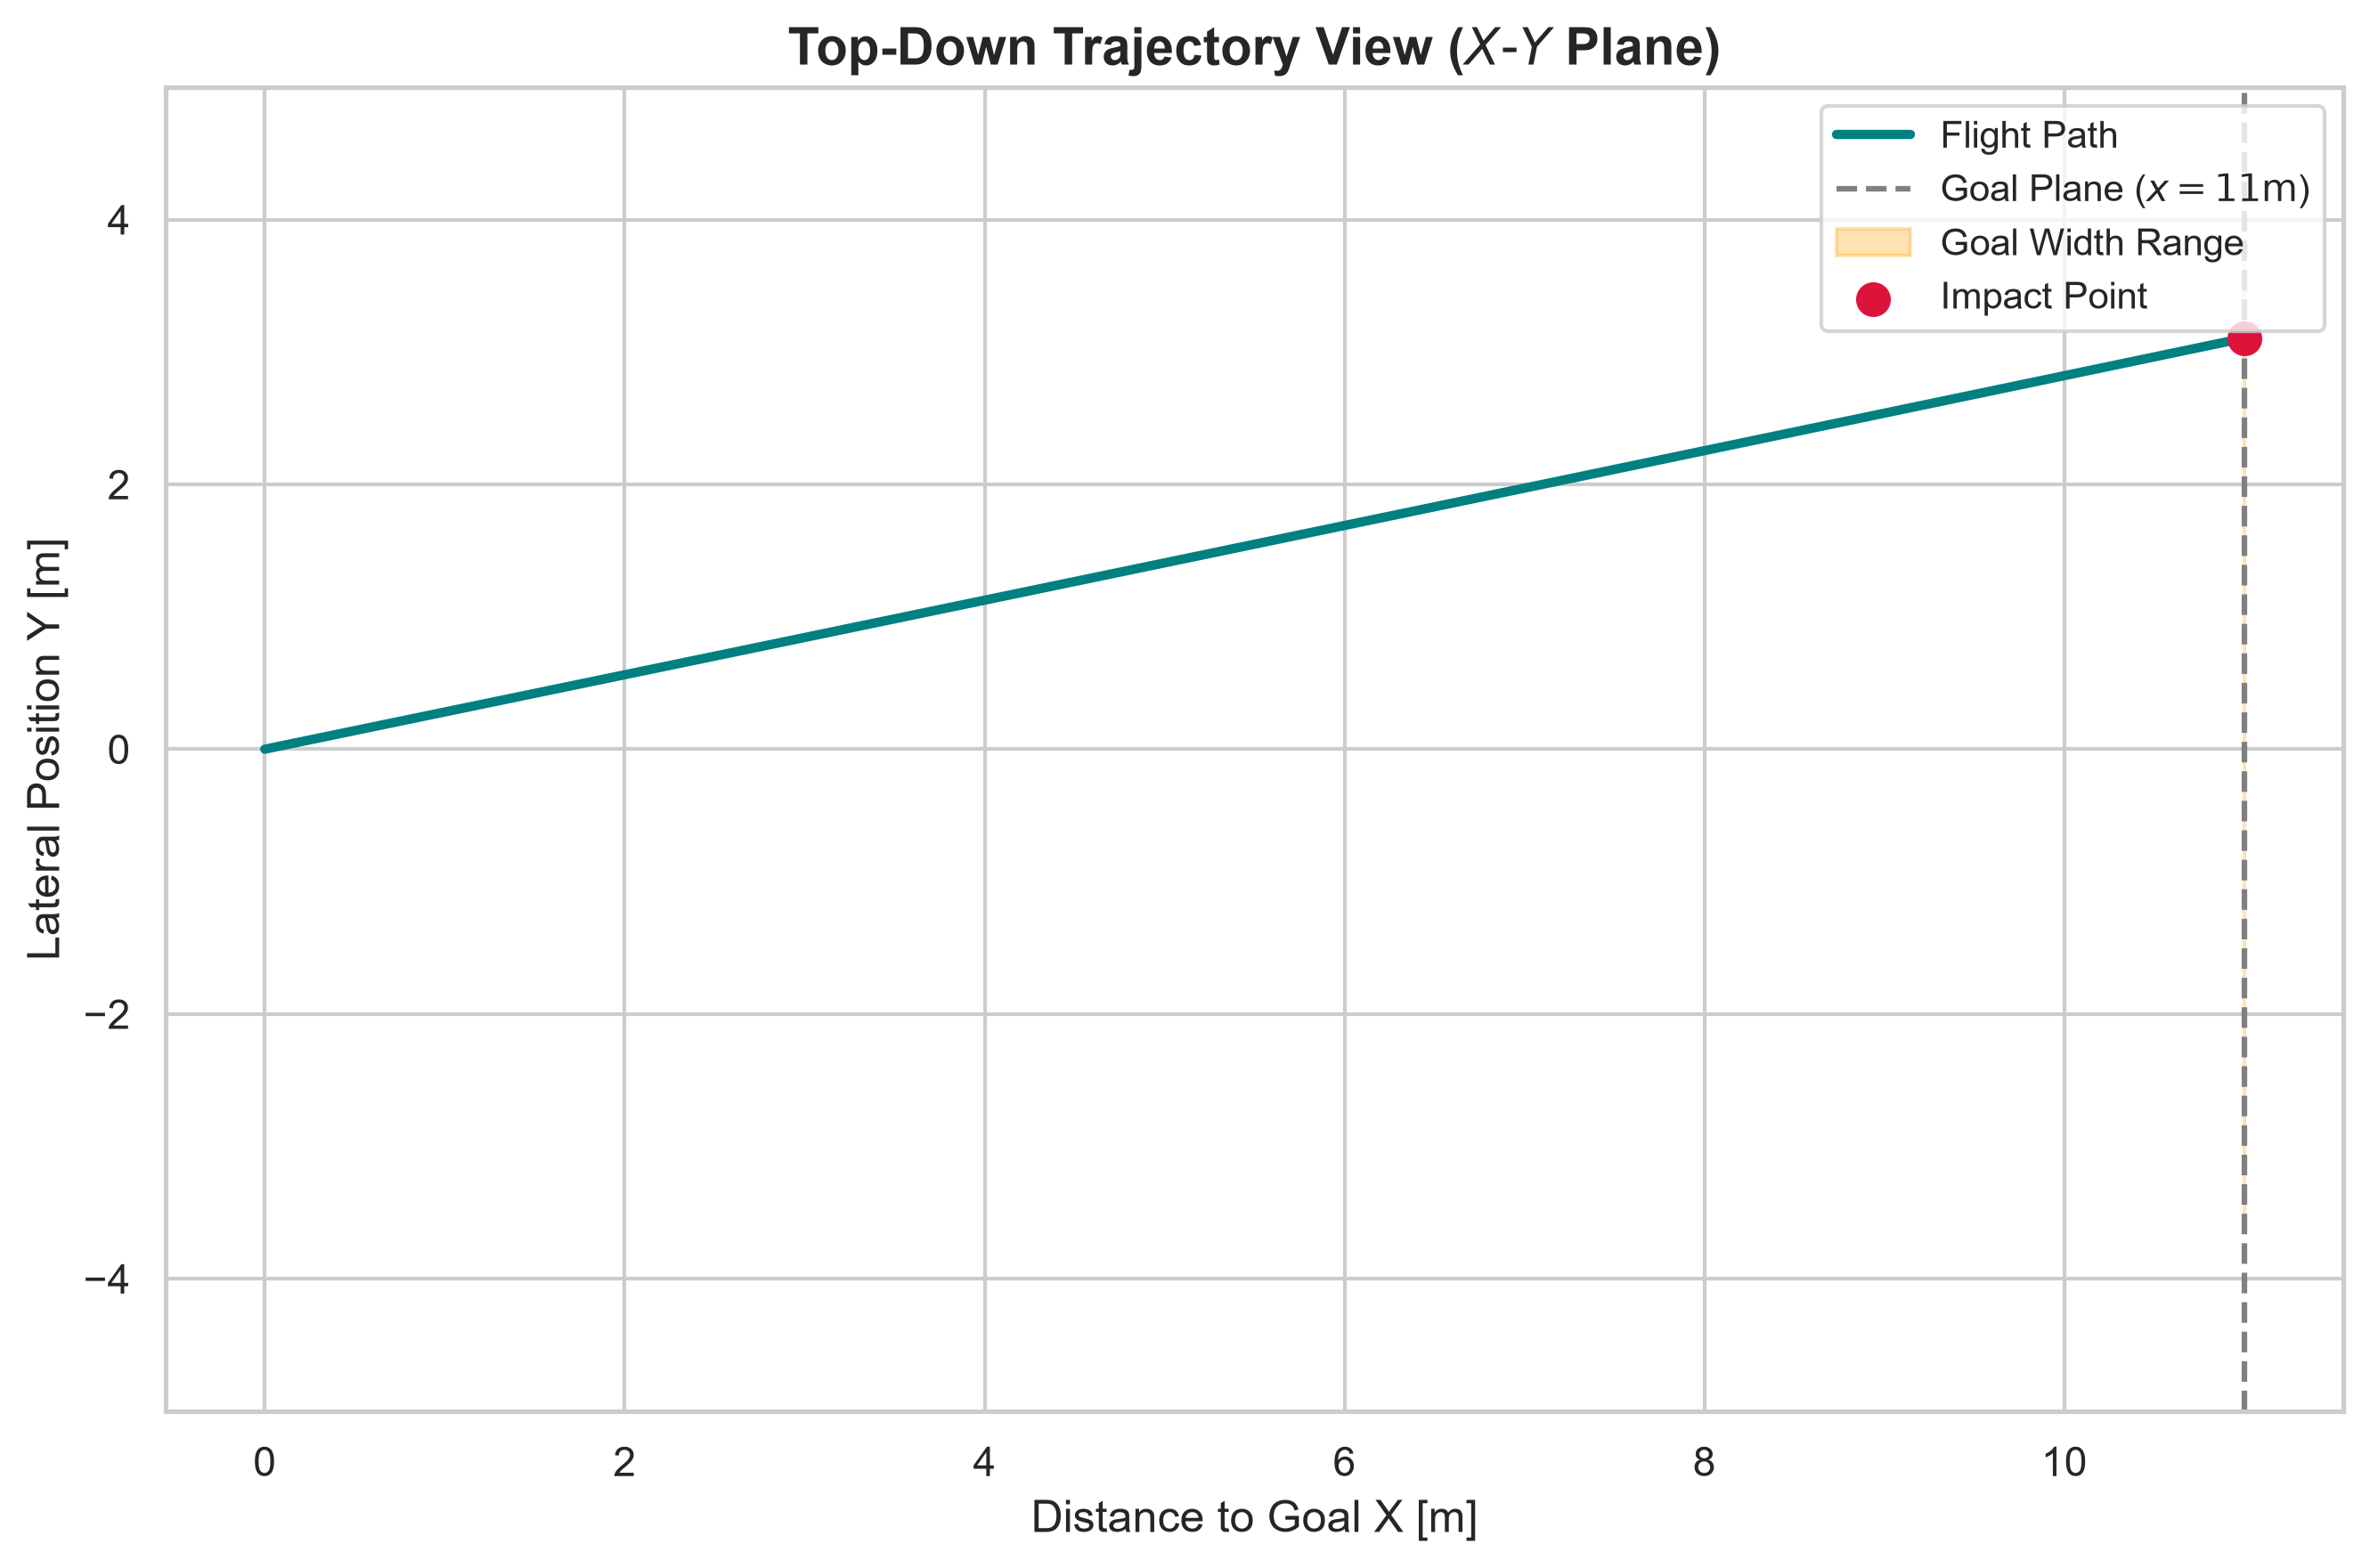

In [42]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x_traj, y_traj, color='teal', lw=2.5, label='Flight Path')
ax.axvline(11.0, color='gray', linestyle='--', label='Goal Plane ($x=11\\text{m}$)')
ax.fill_between([11.0, 11.0], -3.66, 3.66, color='orange', alpha=0.3, label='Goal Width Range')
ax.scatter([11.0], [final_y], color='crimson', s=70, zorder=5, label='Impact Point')

ax.set_title("Top-Down Trajectory View ($X\\text{-}Y$ Plane)", fontsize=14, fontweight='bold')
ax.set_xlabel("Distance to Goal X [m]")
ax.set_ylabel("Lateral Position Y [m]")
ax.set_ylim(-5, 5)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

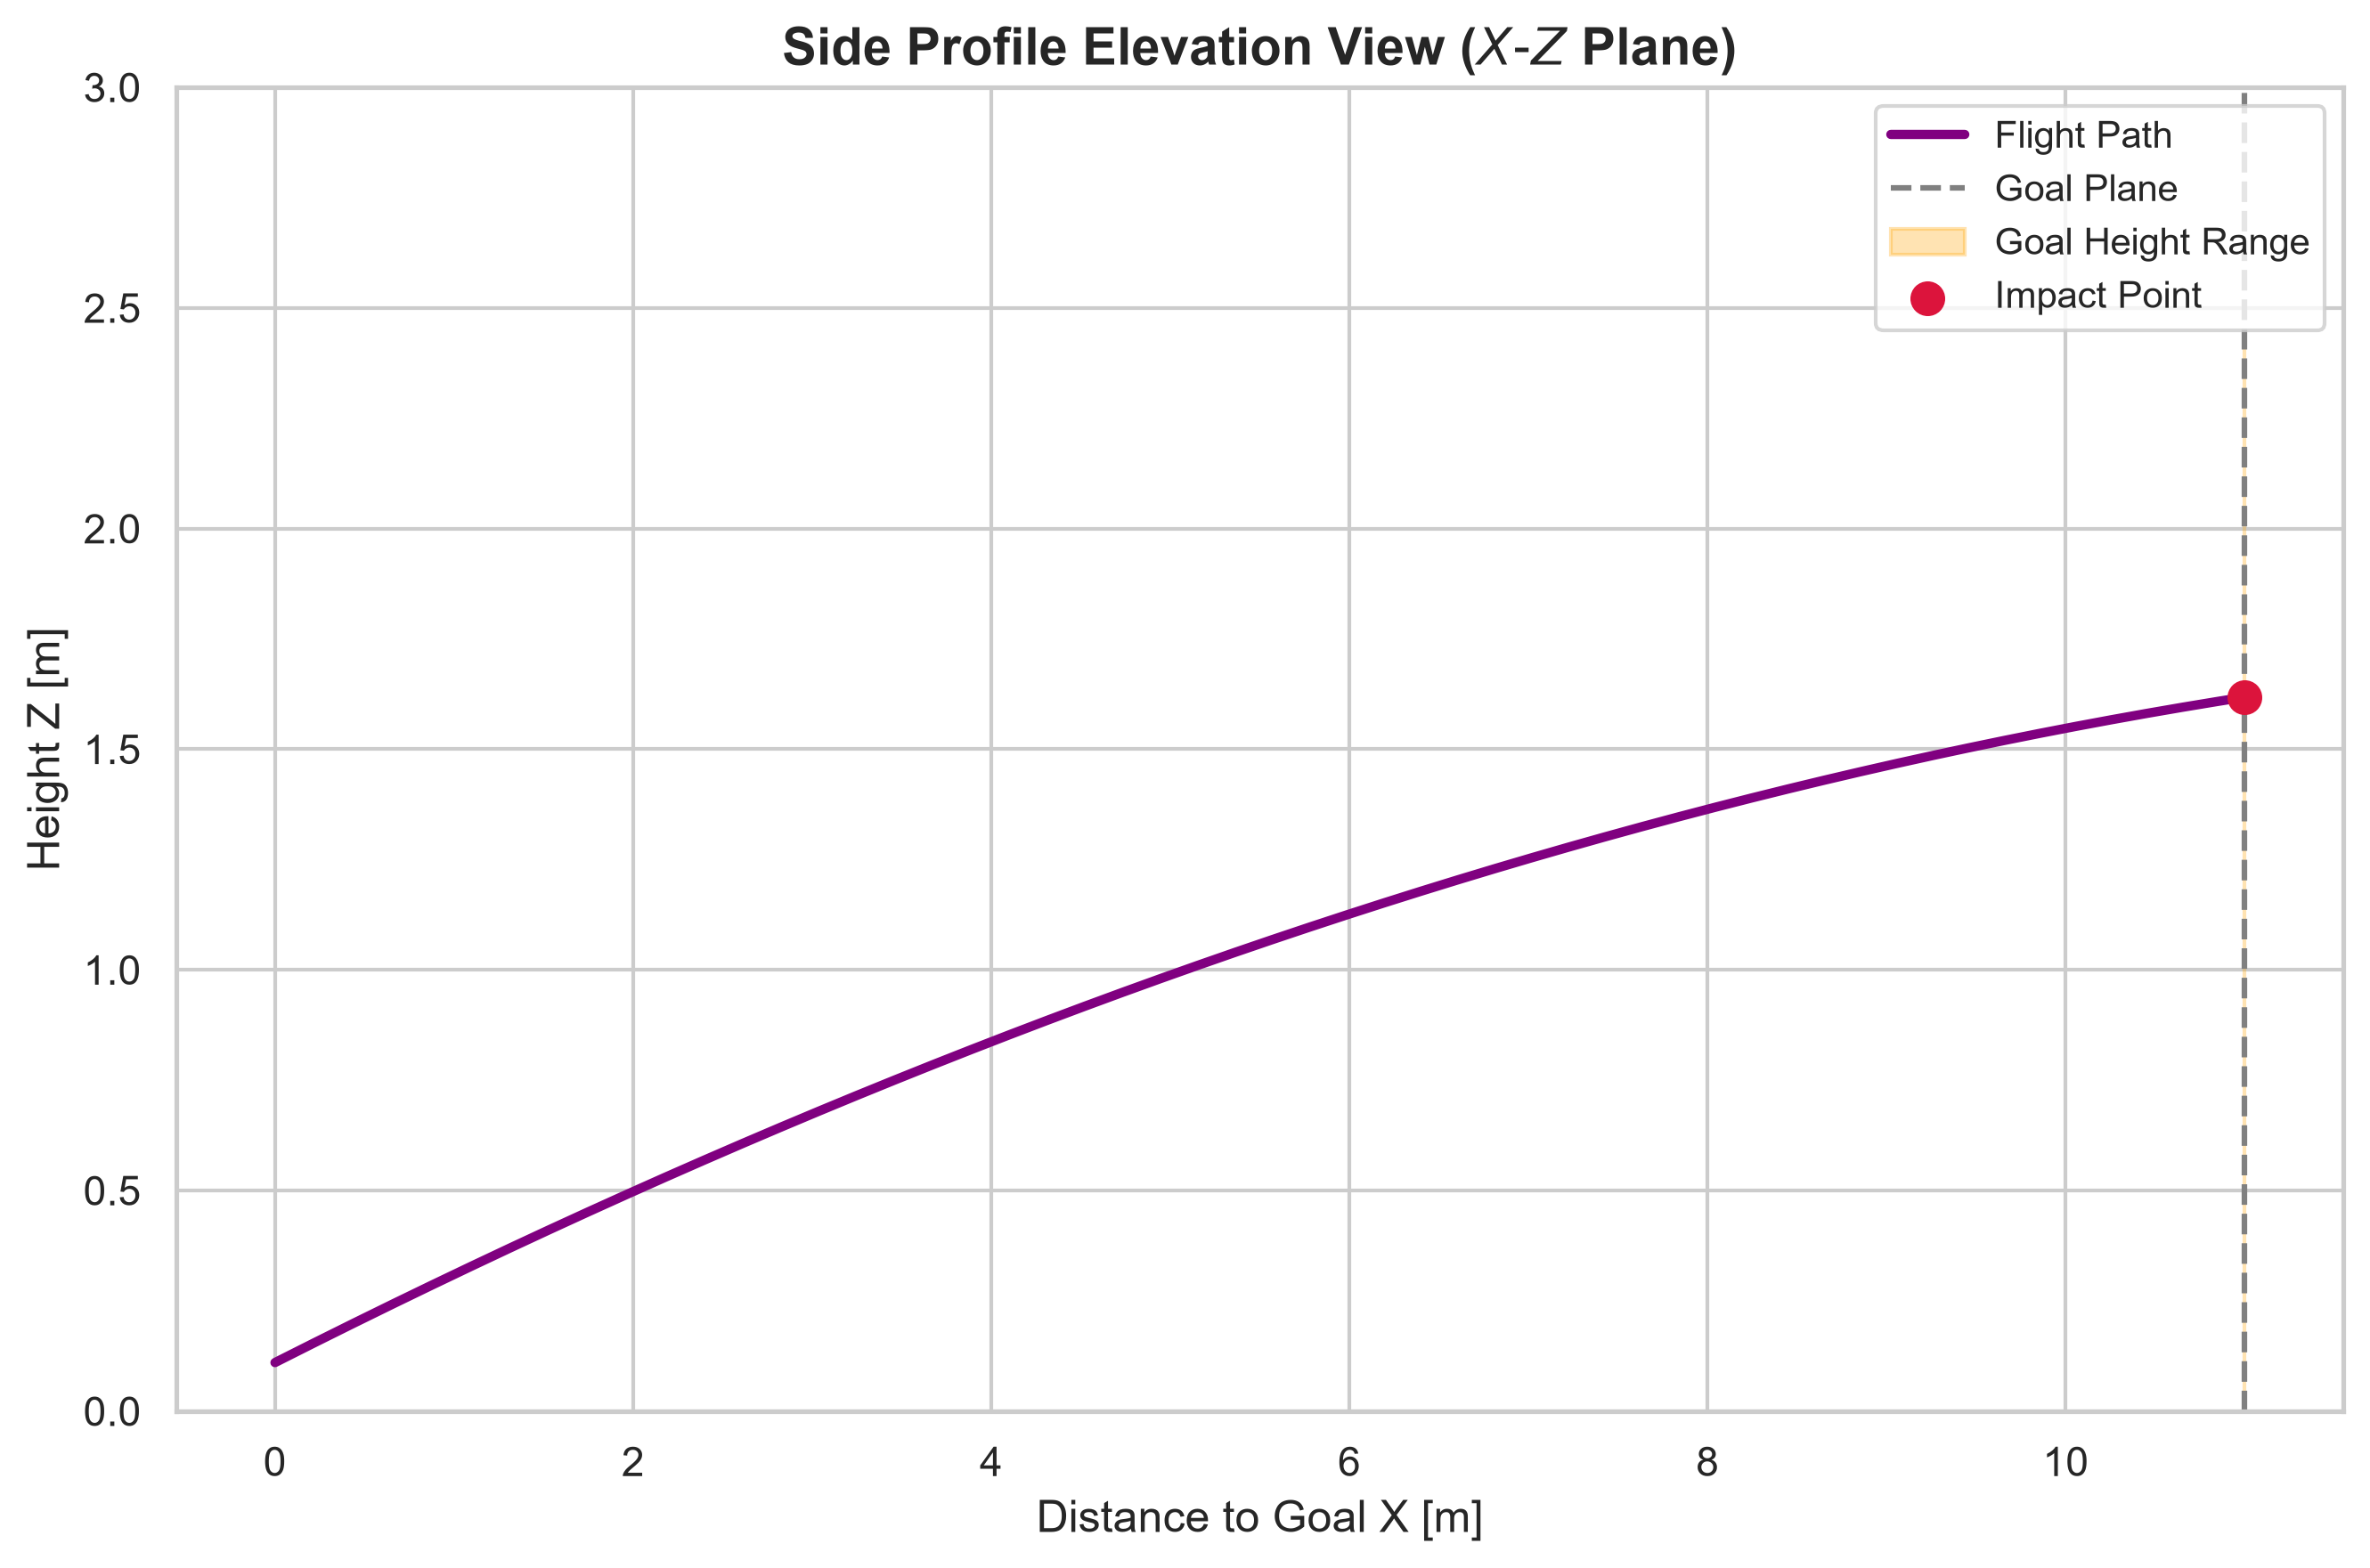

In [43]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x_traj, z_traj, color='purple', lw=2.5, label='Flight Path')
ax.axvline(11.0, color='gray', linestyle='--', label='Goal Plane')
ax.fill_between([11.0, 11.0], 0, 2.44, color='orange', alpha=0.3, label='Goal Height Range')
ax.scatter([11.0], [final_z], color='crimson', s=70, zorder=5, label='Impact Point')

ax.set_title("Side Profile Elevation View ($X\\text{-}Z$ Plane)", fontsize=14, fontweight='bold')
ax.set_xlabel("Distance to Goal X [m]")
ax.set_ylabel("Height Z [m]")
ax.set_ylim(0, 3)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

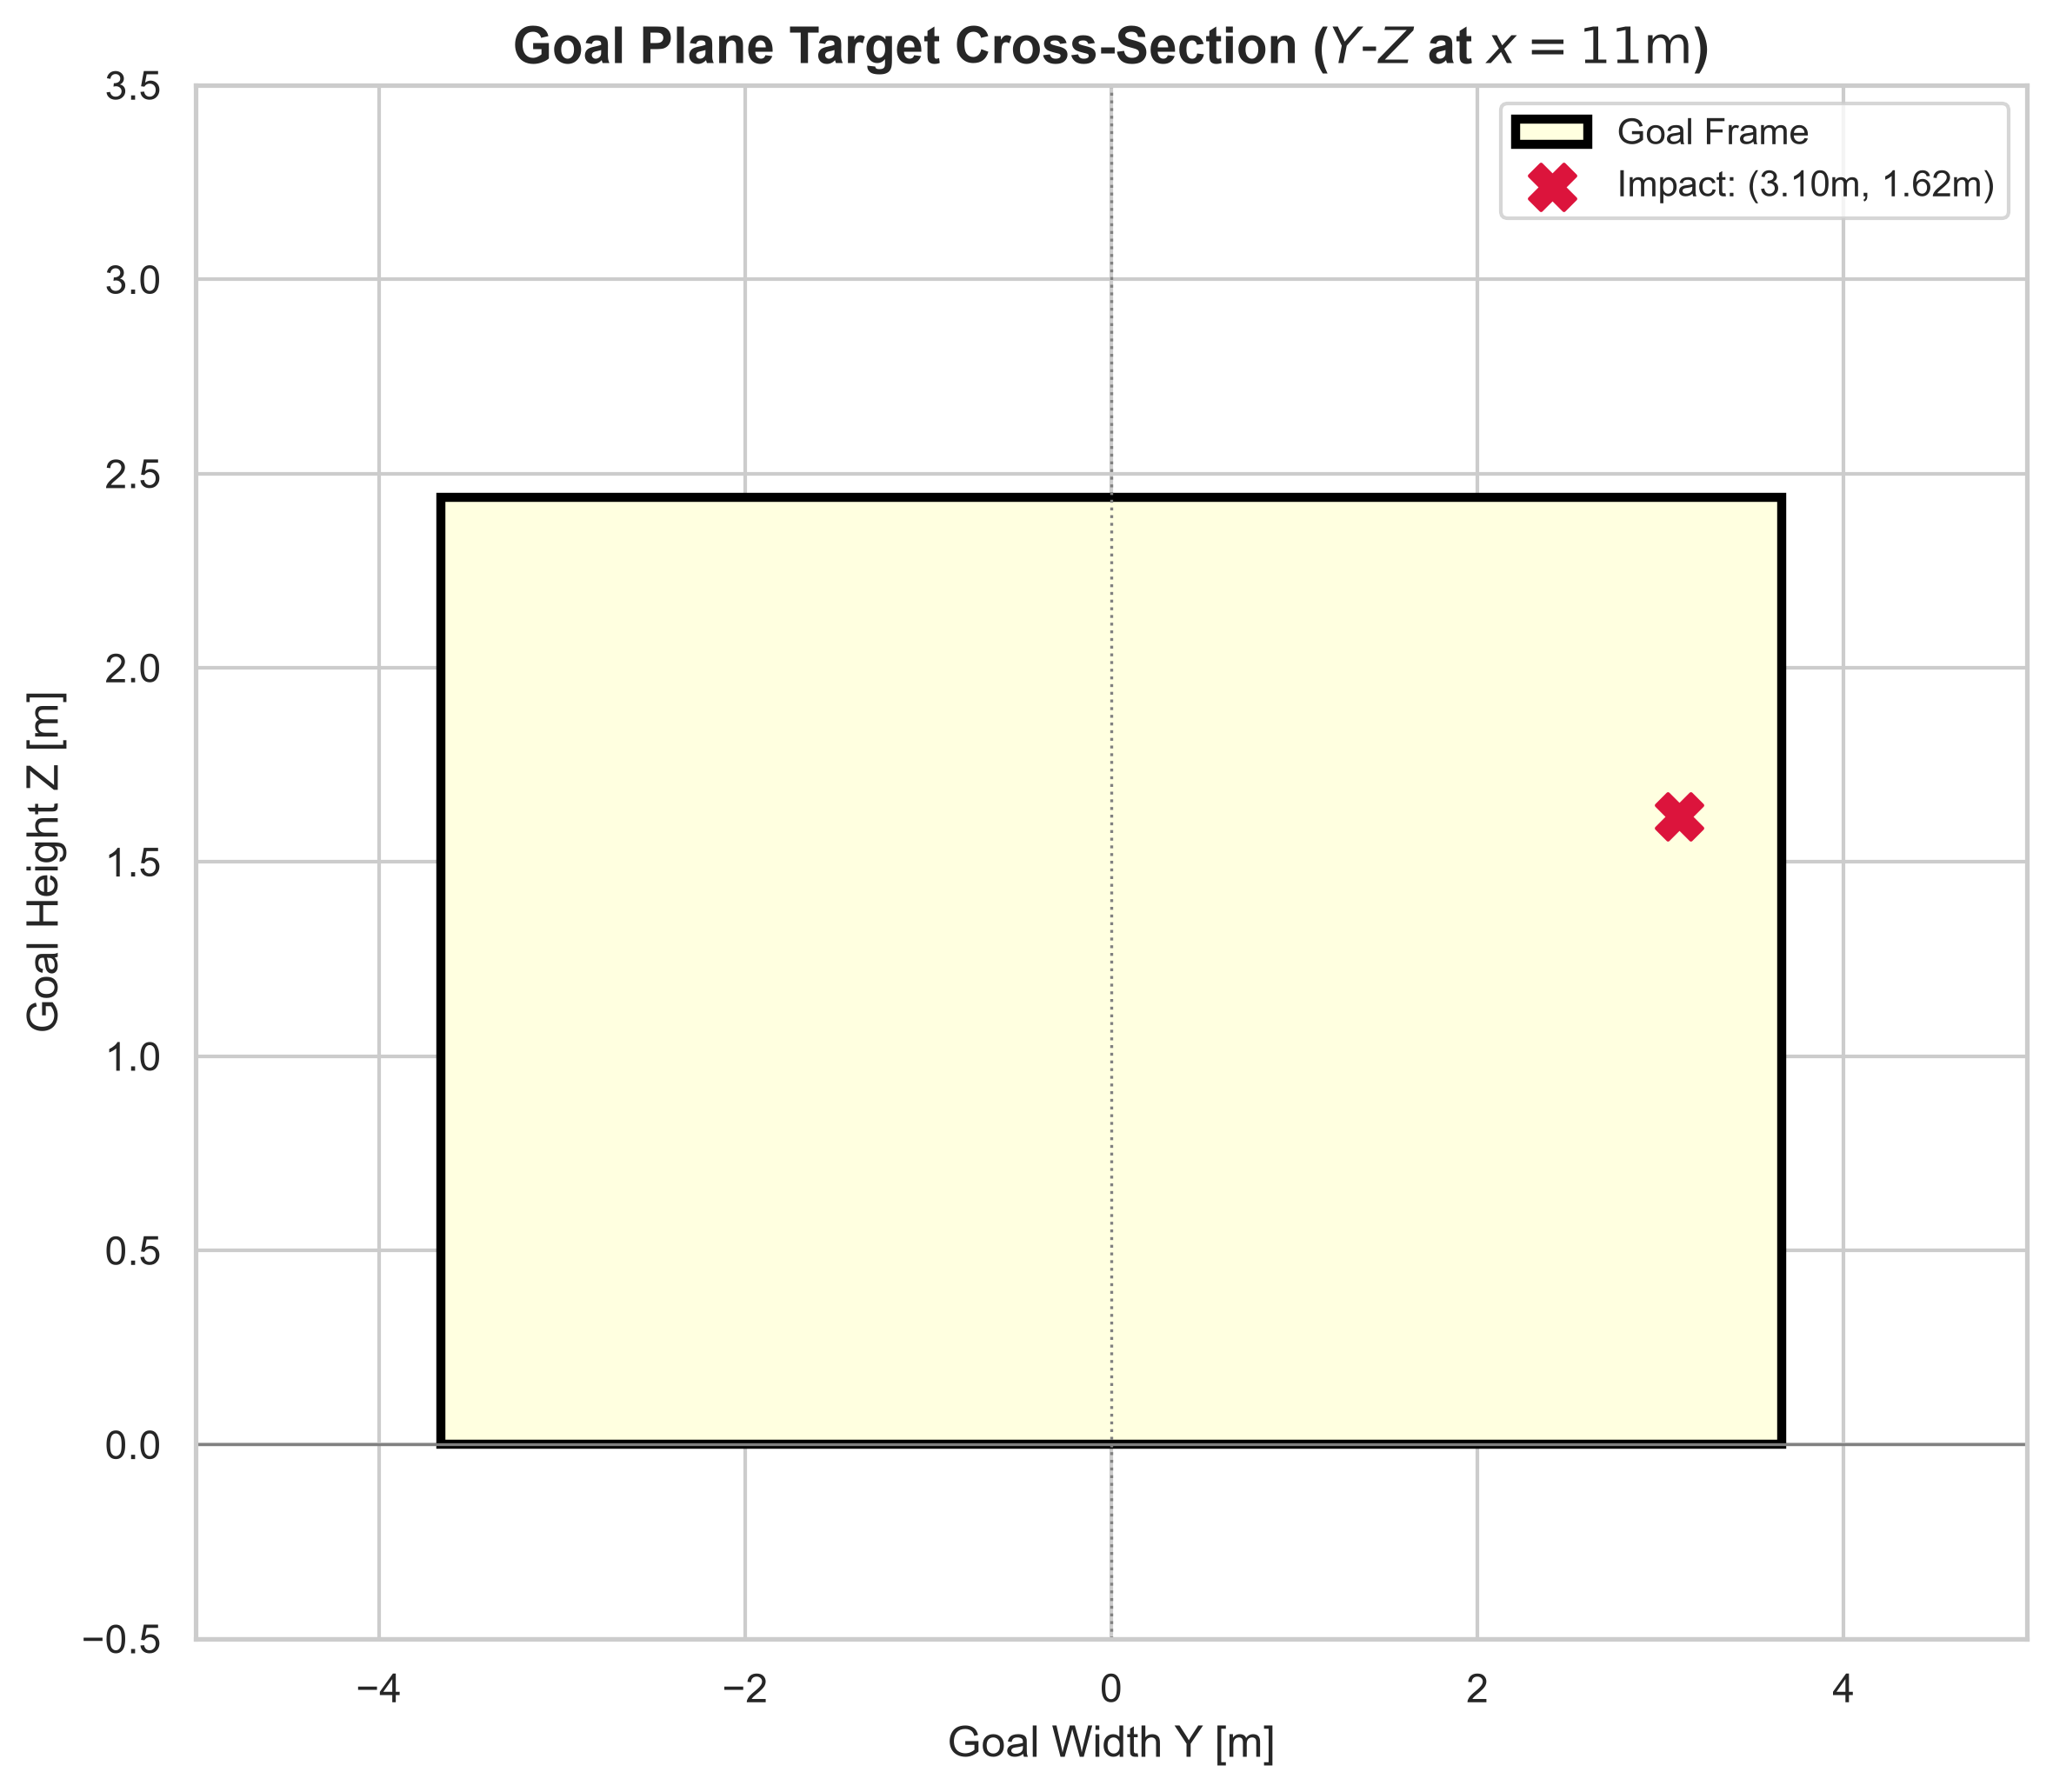

In [44]:
fig, ax = plt.subplots(figsize=(8, 7))


goal_rect = plt.Rectangle((-3.66, 0.0), 7.32, 2.44, linewidth=2.5, edgecolor='black', facecolor='lightyellow', label='Goal Frame')
ax.add_patch(goal_rect)


ax.scatter([final_y], [final_z], color='crimson', s=160, marker='X', zorder=5, label=f"Impact: ({final_y:.2f}m, {final_z:.2f}m)")

ax.set_title("Goal Plane Target Cross-Section ($Y\\text{-}Z$ at $x=11\\text{m}$)", fontsize=14, fontweight='bold')
ax.set_xlabel("Goal Width Y [m]")
ax.set_ylabel("Goal Height Z [m]")
ax.set_xlim(-5.0, 5.0)
ax.set_ylim(-0.5, 3.5)
ax.axhline(0, color='gray', linewidth=0.8)
ax.axvline(0, color='gray', linewidth=0.8, linestyle=':')
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()